<a href="https://colab.research.google.com/github/pehagaph/EstruturaDeDados/blob/main/Sistema_Especialista_MMA_IA_LFA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Sistema Especialista Híbrido: Consultor Tático de MMA (Gameplan)
**Disciplina:** Inteligência Artificial e Linguagens Formais e Autômatos (IA/LFA) — Profa. Kadidja Valéria  
**Aluno:** Paulo Henrique Santos Lopes — Engenharia de Software (UDF)

---
## 1. Estudo Inicial (Conceitos Fundamentais)

* **O que é Aprendizado de Máquina (Machine Learning)?** É uma subárea da Inteligência Artificial em que algoritmos identificam padrões estatísticos a partir de exemplos históricos para tomar decisões ou fazer previsões em novos casos, sem que um humano precise programar manualmente cada regra de decisão.
* **O que caracteriza o Aprendizado Supervisionado?** O modelo é treinado com um conjunto de dados rotulados, ou seja, pares contendo as entradas (*atributos*) e a resposta correta já conhecida (*rótulo*), aprendendo a mapear entradas para saídas.
* **O que são atributos e rótulos?** **Atributos (`X`)** são as variáveis de entrada usadas para descrever cada exemplo (no projeto: `golpes_significativos_min` e `quedas_por_luta`). **Rótulo (`y`)** é a resposta ou categoria alvo que queremos prever (no projeto: `estilo_oponente`, classificado como `striker` ou `grappler`).
* **Como classificação difere de regressão?** Na **classificação**, o modelo prevê uma categoria discreta (ex.: `striker` vs. `grappler`). Na **regressão**, o modelo prevê um valor numérico contínuo (ex.: estimar quantos golpes exatos um lutador conectará em 3 rounds).
* **Por que separar treino e teste?** Para avaliar se o modelo realmente aprendeu padrões generalizáveis em dados inéditos (`X_teste`), em vez de apenas memorizar os exemplos vistos durante o treinamento (`X_treino`).

## 2. Definição do Problema e do Dataset Simulado

* **Público e Finalidade:** Treinadores de corner e analistas de desempenho no MMA que precisam definir a estratégia inicial (*gameplan*) para enfrentar um adversário.
* **Entradas e Rótulo:** O modelo supervisionado recebe duas estatísticas médias por luta do adversário — **golpes significativos conectados por minuto** (`golpes_significativos_min`) e **média de quedas aplicadas a cada 15 minutos** (`quedas_por_luta`) — e prevê o estilo predominante (`striker` ou `grappler`). Na consulta ao Sistema Especialista, informa-se um fato contextual da luta: se o nosso atleta tem **vantagem de envergadura** (`envergadura_maior`: `True` ou `False`).
* **Origem e Critérios de Rotulagem do Dataset:** O dataset contém **16 registros simulados** (8 `striker` e 8 `grappler`), construídos exclusivamente para fins didáticos com base em faixas típicas de métricas de combate: atletas com alto volume de golpes em pé (> 4,5/min) e poucas quedas (≤ 1,0) foram rotulados como `striker`, enquanto atletas com maior volume de quedas (≥ 2,8) e menor volume em pé (≤ 3,1) foram rotulados como `grappler`.

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# Dataset simulado (16 registros fictícios para fins didáticos)
dados = pd.DataFrame({
    "golpes_significativos_min": [5.8, 6.2, 4.9, 5.5, 6.7, 5.1, 4.6, 6.0, 2.1, 1.8, 2.9, 2.4, 1.5, 3.1, 2.6, 2.0],
    "quedas_por_luta":           [0.4, 0.2, 0.8, 0.5, 0.1, 1.0, 0.9, 0.3, 3.8, 4.5, 3.1, 4.2, 5.0, 2.8, 3.5, 4.7],
    "estilo_oponente":           ["striker"] * 8 + ["grappler"] * 8
})

print("=== DATASET SIMULADO (MMA) ===")
print(dados.to_string(index=False))
print("\nQuantidade por classe:")
print(dados["estilo_oponente"].value_counts())

=== DATASET SIMULADO (MMA) ===
 golpes_significativos_min  quedas_por_luta estilo_oponente
                       5.8              0.4         striker
                       6.2              0.2         striker
                       4.9              0.8         striker
                       5.5              0.5         striker
                       6.7              0.1         striker
                       5.1              1.0         striker
                       4.6              0.9         striker
                       6.0              0.3         striker
                       2.1              3.8        grappler
                       1.8              4.5        grappler
                       2.9              3.1        grappler
                       2.4              4.2        grappler
                       1.5              5.0        grappler
                       3.1              2.8        grappler
                       2.6              3.5        grappler
         

In [7]:
# Separação entre atributos (X) e rótulo (y)
X = dados[["golpes_significativos_min", "quedas_por_luta"]]
y = dados["estilo_oponente"]

# Divisão: 75% treino (12 exemplos) e 25% teste (4 exemplos) com estratificação
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print(f"Tamanho do treino: {len(X_treino)} | Tamanho do teste: {len(X_teste)}")

Tamanho do treino: 12 | Tamanho do teste: 4


Acurácia no teste: 100.0%

Matriz de Confusão:
          striker  grappler
striker         2         0
grappler        0         2


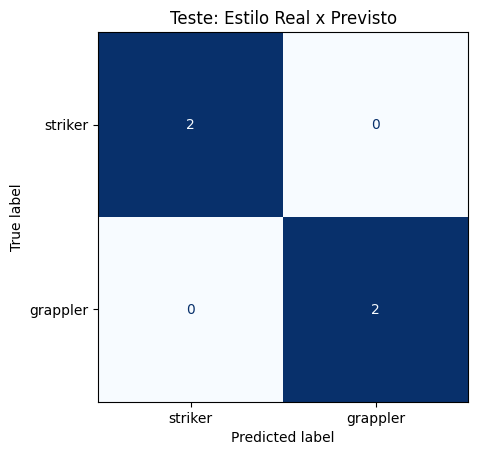

Condições aprendidas pela árvore:
|--- golpes_significativos_min <= 4.00
|   |--- class: grappler
|--- golpes_significativos_min >  4.00
|   |--- class: striker



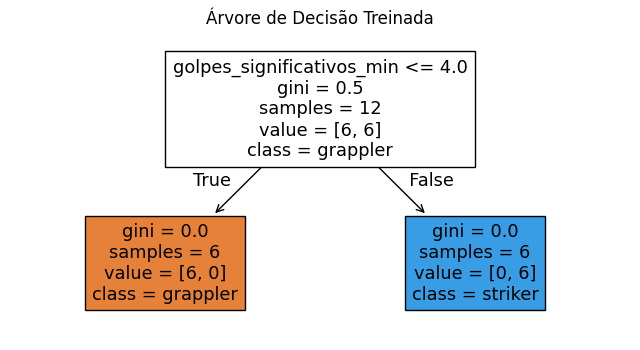

In [8]:
# Treinamento da Árvore de Decisão
modelo = DecisionTreeClassifier(max_depth=2, random_state=42)
modelo.fit(X_treino, y_treino)

# Avaliação no conjunto de teste
previsoes = modelo.predict(X_teste)
print(f"Acurácia no teste: {accuracy_score(y_teste, previsoes):.1%}")

classes = ["striker", "grappler"]
matriz = confusion_matrix(y_teste, previsoes, labels=classes)
print("\nMatriz de Confusão:")
print(pd.DataFrame(matriz, index=classes, columns=classes))

ConfusionMatrixDisplay(matriz, display_labels=classes).plot(cmap="Blues", colorbar=False)
plt.title("Teste: Estilo Real x Previsto")
plt.show()

print("Condições aprendidas pela árvore:")
print(export_text(modelo, feature_names=list(X.columns)))

plt.figure(figsize=(8, 4))
plot_tree(modelo, feature_names=list(X.columns), class_names=list(modelo.classes_), filled=True)
plt.title("Árvore de Decisão Treinada")
plt.show()

## 3. Base de Conhecimento e Motor de Inferência

As quatro regras abaixo representam o conhecimento tático explícito de um treinador de MMA (heurística do especialista), cruzando o estilo previsto pelo modelo de Machine Learning com a vantagem física de envergadura do nosso atleta:

* **R1:** `SE estilo_oponente = striker E envergadura_maior = True, ENTÃO manter a longa distância com jabs, chutes baixos (low kicks) e controle do centro do octógono.`
* **R2:** `SE estilo_oponente = striker E envergadura_maior = False, ENTÃO encurtar a distância com pressão no clinch na grade e buscar quedas para neutralizar a trocação.`
* **R3:** `SE estilo_oponente = grappler E envergadura_maior = True, ENTÃO circular lateralmente usando golpes retos longos e defesa de quedas (sprawl) para manter a luta em pé.`
* **R4:** `SE estilo_oponente = grappler E envergadura_maior = False, ENTÃO trabalhar contragolpes curtos com base baixa, foco em esgrima (underhooks) e jiu-jítsu defensivo.`

In [9]:
# Base de conhecimento (regras simbólicas)
regras = [
    {
        "id": "R1",
        "estilo_oponente": "striker",
        "envergadura_maior": True,
        "acao": "Manter a longa distância com jabs, chutes baixos (low kicks) e controle do centro do octógono."
    },
    {
        "id": "R2",
        "estilo_oponente": "striker",
        "envergadura_maior": False,
        "acao": "Encurtar a distância com pressão no clinch na grade e buscar quedas para neutralizar a trocação."
    },
    {
        "id": "R3",
        "estilo_oponente": "grappler",
        "envergadura_maior": True,
        "acao": "Circular lateralmente usando golpes retos longos e defesa de quedas (sprawl) para manter a luta em pé."
    },
    {
        "id": "R4",
        "estilo_oponente": "grappler",
        "envergadura_maior": False,
        "acao": "Trabalhar contragolpes curtos com base baixa, foco em esgrima (underhooks) e jiu-jítsu defensivo."
    }
]

# Motor de inferência (encadeamento para frente com módulo de explicação)
def aplicar_regras(estilo_oponente, envergadura_maior):
    for regra in regras:
        if (regra["estilo_oponente"] == estilo_oponente and
                regra["envergadura_maior"] == envergadura_maior):
            return {
                "estilo_previsto": estilo_oponente,
                "regra_aplicada": regra["id"],
                "recomendacao": regra["acao"],
                "explicacao": (
                    f"Estilo previsto pelo modelo: '{estilo_oponente}'; "
                    f"vantagem de envergadura do nosso atleta: {envergadura_maior}."
                )
            }
    raise ValueError("Nenhuma regra compatível com os fatos informados.")

In [10]:
# Função de integração (ML -> Fato -> Sistema Especialista)
def orientar_estrategia_mma(golpes_min, quedas, envergadura_maior):
    if not 0 <= golpes_min <= 20:
        raise ValueError("Golpes significativos por minuto devem estar entre 0 e 20.")
    if not 0 <= quedas <= 15:
        raise ValueError("Quedas por luta devem estar entre 0 e 15.")
    if not isinstance(envergadura_maior, bool):
        raise ValueError("envergadura_maior deve ser True ou False.")

    novo_caso = pd.DataFrame([{
        "golpes_significativos_min": golpes_min,
        "quedas_por_luta": quedas
    }])

    estilo = modelo.predict(novo_caso)[0]
    resultado = aplicar_regras(estilo, envergadura_maior)

    fora = any(
        not (X_treino[c].min() <= novo_caso[c].iloc[0] <= X_treino[c].max())
        for c in X.columns
    )
    resultado["aviso"] = (
        "Entrada fora dos intervalos observados no treino."
        if fora else "Exemplo didático; estratégia sujeita à revisão do treinador."
    )
    return resultado

# Demonstração com 3 novos casos inéditos
casos = [
    (5.6, 0.4, False),  # Caso 1: oponente striker, mas nosso lutador tem menor envergadura
    (2.2, 4.0, True),   # Caso 2: oponente grappler e nosso lutador tem maior envergadura
    (6.1, 0.3, True)    # Caso 3: oponente striker e nosso lutador tem maior envergadura
]

for i, (golpes, quedas, env) in enumerate(casos, 1):
    print(f"\nCASO {i}: {golpes} golpes/min | {quedas} quedas/luta | envergadura_maior={env}")
    for campo, valor in orientar_estrategia_mma(golpes, quedas, env).items():
        print(f"  {campo}: {valor}")


CASO 1: 5.6 golpes/min | 0.4 quedas/luta | envergadura_maior=False
  estilo_previsto: striker
  regra_aplicada: R2
  recomendacao: Encurtar a distância com pressão no clinch na grade e buscar quedas para neutralizar a trocação.
  explicacao: Estilo previsto pelo modelo: 'striker'; vantagem de envergadura do nosso atleta: False.
  aviso: Exemplo didático; estratégia sujeita à revisão do treinador.

CASO 2: 2.2 golpes/min | 4.0 quedas/luta | envergadura_maior=True
  estilo_previsto: grappler
  regra_aplicada: R3
  recomendacao: Circular lateralmente usando golpes retos longos e defesa de quedas (sprawl) para manter a luta em pé.
  explicacao: Estilo previsto pelo modelo: 'grappler'; vantagem de envergadura do nosso atleta: True.
  aviso: Exemplo didático; estratégia sujeita à revisão do treinador.

CASO 3: 6.1 golpes/min | 0.3 quedas/luta | envergadura_maior=True
  estilo_previsto: striker
  regra_aplicada: R1
  recomendacao: Manter a longa distância com jabs, chutes baixos (low kicks) 

## 4. Análise dos Resultados, Limitações e Perguntas de Estudo

### Análise dos Três Casos Testados
* **Caso 1 (`5.6 golpes/min`, `0.4 quedas`, `envergadura_maior=False`):** Como o volume de golpes em pé é alto (`> 4.0`), o modelo previu `striker`. Cruzando esse fato com a desvantagem de alcance (`False`), o motor disparou a regra **R2**, recomendando encurtar e buscar o clinch/quedas.
* **Caso 2 (`2.2 golpes/min`, `4.0 quedas`, `envergadura_maior=True`):** Pelo baixo volume em pé (`<= 4.0`), o modelo previu `grappler`. Como nosso atleta tem maior alcance (`True`), o motor disparou a regra **R3**, orientando manter a distância com golpes retos e *sprawl*.
* **Caso 3 (`6.1 golpes/min`, `0.3 quedas`, `envergadura_maior=True`):** O modelo previu `striker` e, somado à vantagem de alcance (`True`), disparou a regra **R1** (controle de distância com jabs e chutes baixos).

### Respostas às Perguntas de Análise
1. **Qual parte do programa aprende com os dados e qual parte aplica regras humanas?** A árvore de decisão (`DecisionTreeClassifier` no método `fit()`) aprende padrões a partir dos dados rotulados. Já a lista `regras` e a função `aplicar_regras()` aplicam as regras simbólicas escritas pelo especialista humano.
2. **Por que `envergadura_maior` não aparece entre os atributos (`X`) do modelo?** Porque o objetivo do modelo de ML é classificar apenas o estilo de luta histórico do adversário. A vantagem de envergadura é um fato contextual da comparação entre os dois lutadores naquela luta específica, entrando diretamente na tomada de decisão tática do Sistema Especialista.
3. **O que acontece ao mudar apenas esse fato (`envergadura_maior`)?** A previsão do modelo de ML (`estilo_oponente`) permanece idêntica, pois os números de golpes e quedas não mudaram. Porém, o motor de inferência aciona outra regra na base de conhecimento (por exemplo, sai de **R1** para **R2**), invertendo completamente a estratégia recomendada.
4. **Limitações, representatividade e suficiência de 100% em 4 casos:** Um acerto de 100% em apenas 4 casos de teste **não** é suficiente para uso real. O dataset tem apenas 16 registros fictícios com separação linear simples, ignorando lutadores completos (*all-rounders*), defesa de quedas, resistência cardiovascular e variações de round. Em produção, seria necessário um volume muito maior de dados reais e validação contínua por treinadores.